In [ ]:
import os
import gc
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import lightgbm as lgb
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "data").exists(), "Could not locate project root."

OFFICIAL_ORIGIN = 1913
EVAL_START = 1914
EVAL_END = 1941
FORECAST_HORIZON = 28
N_SERIES = 200

PREDICTION_DIR = (
    PROJECT_ROOT / "data" / "processed" /
    "official_evaluation" / "predictions"
)

MODEL_DIR = PROJECT_ROOT / "models" / "official_evaluation"
RESULT_DIR = PROJECT_ROOT / "results" / "official_evaluation"

for directory in [PREDICTION_DIR, MODEL_DIR, RESULT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

DAILY_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "daily_model_features.parquet"
)

LGB_CONFIG_PATH = (
    PROJECT_ROOT / "models" / "lightgbm" /
    "artifacts" / "lightgbm_model_config.json"
)

LGB_TRAIN_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "lightgbm_corrected" / "fold_5_train.parquet"
)

LGB_VALIDATION_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "lightgbm_corrected" / "fold_5_validation.parquet"
)

LSTM_DATA_DIR = (
    PROJECT_ROOT / "data" / "processed" /
    "lstm" / "processed_datasets"
)

LSTM_CONFIG_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "lstm" / "lstm_dataset_config.json"
)

TFT_TRAIN_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "tft" / "official_evaluation_training.pt"
)

TFT_VALIDATION_PATH = (
    PROJECT_ROOT / "data" / "processed" /
    "tft" / "official_evaluation_validation.pt"
)

SEED = 42
QUANTILES = (0.1, 0.5, 0.9)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)
print("Daily panel exists:", DAILY_PATH.exists())
print("LightGBM train exists:", LGB_TRAIN_PATH.exists())
print("LightGBM validation exists:", LGB_VALIDATION_PATH.exists())
print("LSTM config exists:", LSTM_CONFIG_PATH.exists())
print("TFT training exists:", TFT_TRAIN_PATH.exists())
print("TFT validation exists:", TFT_VALIDATION_PATH.exists())

Project root: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence
Device: cpu
Daily panel exists: True
LightGBM train exists: True
LightGBM validation exists: True
LSTM config exists: True
TFT training exists: True
TFT validation exists: True


In [3]:
LSTM_TRAIN_PATH = LSTM_DATA_DIR / "official_evaluation_train.npz"
LSTM_EVAL_PATH = LSTM_DATA_DIR / "official_evaluation_evaluation.npz"

assert LSTM_TRAIN_PATH.exists(), LSTM_TRAIN_PATH
assert LSTM_EVAL_PATH.exists(), LSTM_EVAL_PATH

def load_npz_arrays(path):
    with np.load(path, allow_pickle=True) as data:
        return {key: data[key] for key in data.files}

lstm_train_arrays = load_npz_arrays(LSTM_TRAIN_PATH)
lstm_eval_arrays = load_npz_arrays(LSTM_EVAL_PATH)

print("Training NPZ keys:", list(lstm_train_arrays.keys()))
print("Evaluation NPZ keys:", list(lstm_eval_arrays.keys()))

SERIES_IDS = np.asarray(lstm_eval_arrays["series_ids"]).astype(str)

assert len(SERIES_IDS) == N_SERIES
assert len(np.unique(SERIES_IDS)) == N_SERIES

print("Selected series:", len(SERIES_IDS))
print("Evaluation origin:", np.unique(lstm_eval_arrays["evaluation_origin"]))
print("Historical numeric:", lstm_train_arrays["historical_numeric"].shape)
print("Historical categorical:", lstm_train_arrays["historical_categorical"].shape)
print("Future numeric:", lstm_train_arrays["future_numeric"].shape)
print("Future categorical:", lstm_train_arrays["future_categorical"].shape)
print("Static categorical:", lstm_train_arrays["static_categorical"].shape)
print("Training target:", lstm_train_arrays["target_sales"].shape)

Training NPZ keys: ['historical_numeric', 'historical_categorical', 'future_numeric', 'future_categorical', 'static_categorical', 'target_sales', 'series_ids', 'origins']
Evaluation NPZ keys: ['historical_numeric', 'historical_categorical', 'future_numeric', 'future_categorical', 'static_categorical', 'target_sales', 'series_ids', 'evaluation_origin']
Selected series: 200
Evaluation origin: [1913]
Historical numeric: (53200, 56, 14)
Historical categorical: (53200, 56, 3)
Future numeric: (53200, 28, 9)
Future categorical: (53200, 28, 3)
Static categorical: (53200, 5)
Training target: (53200, 28)


In [4]:
con = duckdb.connect()

selected_ids_df = pd.DataFrame({"id": SERIES_IDS})
con.register("selected_ids", selected_ids_df)

actuals_df = con.execute("""
    SELECT
        d.id,
        TRY_CAST(SUBSTRING(d.d, 3) AS INTEGER) AS target_day_num,
        d.sales AS y_true
    FROM read_parquet(?) AS d
    INNER JOIN selected_ids AS s
        ON d.id = s.id
    WHERE TRY_CAST(SUBSTRING(d.d, 3) AS INTEGER)
          BETWEEN ? AND ?
    ORDER BY d.id, target_day_num
""", [
    str(DAILY_PATH),
    EVAL_START,
    EVAL_END
]).df()

history_df = con.execute("""
    SELECT
        d.id,
        TRY_CAST(SUBSTRING(d.d, 3) AS INTEGER) AS day_num,
        d.sales
    FROM read_parquet(?) AS d
    INNER JOIN selected_ids AS s
        ON d.id = s.id
    WHERE TRY_CAST(SUBSTRING(d.d, 3) AS INTEGER)
          BETWEEN ? AND ?
    ORDER BY d.id, day_num
""", [
    str(DAILY_PATH),
    OFFICIAL_ORIGIN - 6,
    OFFICIAL_ORIGIN
]).df()

con.close()
del selected_ids_df
gc.collect()

assert len(actuals_df) == N_SERIES * FORECAST_HORIZON
assert actuals_df["y_true"].notna().all()
assert actuals_df.groupby("id").size().eq(FORECAST_HORIZON).all()
assert len(history_df) == N_SERIES * 7

actuals_df["id"] = actuals_df["id"].astype(str)

history_pivot = history_df.pivot(
    index="id",
    columns="day_num",
    values="sales"
).reindex(SERIES_IDS)

assert history_pivot.shape == (N_SERIES, 7)
assert not history_pivot.isna().any().any()

naive_records = []

for series_id in SERIES_IDS:
    last_seven = history_pivot.loc[series_id].to_numpy(dtype=np.float32)

    for horizon in range(1, FORECAST_HORIZON + 1):
        forecast = last_seven[(horizon - 1) % 7]

        naive_records.append({
            "id": series_id,
            "origin_day_num": OFFICIAL_ORIGIN,
            "target_day_num": OFFICIAL_ORIGIN + horizon,
            "horizon": horizon,
            "p50": float(forecast)
        })

naive_predictions = pd.DataFrame(naive_records)

naive_predictions = naive_predictions.merge(
    actuals_df,
    on=["id", "target_day_num"],
    how="left",
    validate="one_to_one"
)

naive_predictions = naive_predictions[
    ["id", "origin_day_num", "target_day_num",
     "horizon", "y_true", "p50"]
]

assert len(naive_predictions) == 5600
assert naive_predictions["y_true"].notna().all()

naive_predictions.to_parquet(
    PREDICTION_DIR / "seasonal_naive_official_evaluation.parquet",
    index=False
)

print("Seasonal Naive predictions:", naive_predictions.shape)

Seasonal Naive predictions: (5600, 6)


In [61]:
with open(LGB_CONFIG_PATH, "r", encoding="utf-8") as f:
    lgb_config = json.load(f)

MODEL_FEATURES = lgb_config["model_features"]
CATEGORICAL_FEATURES = lgb_config["categorical_features"]

TARGET_COLUMN = lgb_config.get("target_column", "target_sales")

assert len(MODEL_FEATURES) == 32
assert len(CATEGORICAL_FEATURES) == 8

lgb_train = pd.read_parquet(LGB_TRAIN_PATH)
lgb_validation = pd.read_parquet(LGB_VALIDATION_PATH)

lgb_train["id"] = lgb_train["id"].astype(str)
lgb_validation["id"] = lgb_validation["id"].astype(str)

lgb_train = lgb_train[lgb_train["id"].isin(SERIES_IDS)].copy()
lgb_validation = lgb_validation[
    lgb_validation["id"].isin(SERIES_IDS)
].copy()

assert lgb_train["id"].nunique() == N_SERIES
assert lgb_validation["id"].nunique() == N_SERIES
assert lgb_validation["origin_day_num"].nunique() == 1
assert int(lgb_validation["origin_day_num"].iloc[0]) == OFFICIAL_ORIGIN
assert len(lgb_validation) == N_SERIES * FORECAST_HORIZON

assert (lgb_train["target_day_num"] <= OFFICIAL_ORIGIN).all(), (
    "Leakage detected: LightGBM training labels extend beyond d_1913."
)

assert set(MODEL_FEATURES).issubset(lgb_train.columns)
assert set(MODEL_FEATURES).issubset(lgb_validation.columns)

X_train = lgb_train[MODEL_FEATURES].copy()
y_train = lgb_train[TARGET_COLUMN].astype(float)

X_validation = lgb_validation[MODEL_FEATURES].copy()

for column in CATEGORICAL_FEATURES:
    categories = pd.Index(X_train[column].dropna().unique())

    X_train[column] = pd.Categorical(
        X_train[column],
        categories=categories
    )

    X_validation[column] = pd.Categorical(
        X_validation[column],
        categories=categories
    )

assert all(
    isinstance(X_train[column].dtype, pd.CategoricalDtype)
    for column in CATEGORICAL_FEATURES
)

print("LightGBM training rows:", len(X_train))
print("LightGBM validation rows:", len(X_validation))
print("Training label maximum target day:", lgb_train["target_day_num"].max())

LightGBM training rows: 1489600
LightGBM validation rows: 5600
Training label maximum target day: 1913


In [62]:
LGB_ROUNDS = {
    0.1: 110,
    0.5: 175,
    0.9: 380
}

LGB_PARAMS = {
    "objective": "quantile",
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 100,
    "feature_fraction": 0.9,
    "verbosity": -1,
    "seed": SEED,
    "n_jobs": -1
}

lgb_models = {}
lgb_predictions = {}

for quantile in QUANTILES:
    params = {
        **LGB_PARAMS,
        "alpha": quantile,
        "metric": "quantile"
    }

    train_dataset = lgb.Dataset(
        X_train,
        label=y_train,
        categorical_feature=CATEGORICAL_FEATURES,
        free_raw_data=False
    )

    model = lgb.train(
        params=params,
        train_set=train_dataset,
        num_boost_round=LGB_ROUNDS[quantile]
    )

    lgb_models[quantile] = model

    model_path = MODEL_DIR / f"lightgbm_p{int(quantile * 100)}.txt"
    model.save_model(str(model_path))

    lgb_predictions[quantile] = model.predict(
        X_validation,
        num_threads=-1
    )

    print(
        f"Trained P{int(quantile * 100)} "
        f"using {LGB_ROUNDS[quantile]} boosting rounds."
    )

lightgbm_predictions = lgb_validation[
    ["id", "origin_day_num", "target_day_num", "horizon"]
].copy()

lightgbm_predictions["p10"] = lgb_predictions[0.1]
lightgbm_predictions["p50"] = lgb_predictions[0.5]
lightgbm_predictions["p90"] = lgb_predictions[0.9]

lightgbm_predictions = lightgbm_predictions.merge(
    actuals_df,
    on=["id", "target_day_num"],
    how="left",
    validate="one_to_one"
)

lightgbm_predictions = lightgbm_predictions[
    ["id", "origin_day_num", "target_day_num",
     "horizon", "y_true", "p10", "p50", "p90"]
]

assert len(lightgbm_predictions) == 5600
assert lightgbm_predictions[["p10", "p50", "p90"]].notna().all().all()

lightgbm_predictions.to_parquet(
    PREDICTION_DIR / "lightgbm_official_evaluation.parquet",
    index=False
)

del lgb_train, lgb_validation, X_train, X_validation, y_train
gc.collect()

print("LightGBM predictions:", lightgbm_predictions.shape)

Trained P10 using 110 boosting rounds.
Trained P50 using 175 boosting rounds.
Trained P90 using 380 boosting rounds.
LightGBM predictions: (5600, 8)


In [7]:
class RetailDemandDataset(Dataset):
    def __init__(self, arrays):
        self.historical_numeric = torch.tensor(
            arrays["historical_numeric"], dtype=torch.float32
        )
        self.historical_categorical = torch.tensor(
            arrays["historical_categorical"], dtype=torch.long
        )
        self.future_numeric = torch.tensor(
            arrays["future_numeric"], dtype=torch.float32
        )
        self.future_categorical = torch.tensor(
            arrays["future_categorical"], dtype=torch.long
        )
        self.static_categorical = torch.tensor(
            arrays["static_categorical"], dtype=torch.long
        )
        self.target_sales = torch.tensor(
            arrays["target_sales"], dtype=torch.float32
        )

    def __len__(self):
        return len(self.target_sales)

    def __getitem__(self, index):
        return (
            self.historical_numeric[index],
            self.historical_categorical[index],
            self.future_numeric[index],
            self.future_categorical[index],
            self.static_categorical[index],
            self.target_sales[index]
        )


def embedding_dimension(cardinality):
    return min(32, max(4, round(np.sqrt(cardinality) * 2)))


class RetailDemandLSTM(nn.Module):
    def __init__(
        self,
        historical_numeric_dim,
        historical_categorical_cardinalities,
        future_numeric_dim,
        future_categorical_cardinalities,
        static_categorical_cardinalities,
        hidden_size=128,
        num_layers=2,
        dropout=0.15,
        quantiles=(0.1, 0.5, 0.9)
    ):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.historical_embeddings = nn.ModuleList([
            nn.Embedding(
                cardinality,
                embedding_dimension(cardinality),
                padding_idx=0
            )
            for cardinality in historical_categorical_cardinalities
        ])

        self.future_embeddings = nn.ModuleList([
            nn.Embedding(
                cardinality,
                embedding_dimension(cardinality),
                padding_idx=0
            )
            for cardinality in future_categorical_cardinalities
        ])

        self.static_embeddings = nn.ModuleList([
            nn.Embedding(
                cardinality,
                embedding_dimension(cardinality),
                padding_idx=0
            )
            for cardinality in static_categorical_cardinalities
        ])

        historical_embedding_dim = sum(
            embedding_dimension(c)
            for c in historical_categorical_cardinalities
        )

        future_embedding_dim = sum(
            embedding_dimension(c)
            for c in future_categorical_cardinalities
        )

        static_embedding_dim = sum(
            embedding_dimension(c)
            for c in static_categorical_cardinalities
        )

        self.encoder = nn.LSTM(
            input_size=historical_numeric_dim + historical_embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.decoder = nn.LSTM(
            input_size=(
                future_numeric_dim +
                future_embedding_dim +
                static_embedding_dim
            ),
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.dropout = nn.Dropout(dropout)
        self.output_layer = nn.Linear(hidden_size, len(quantiles))

    @staticmethod
    def embed_categories(values, embedding_layers):
        if len(embedding_layers) == 0:
            return values.new_zeros(
                (*values.shape[:2], 0),
                dtype=torch.float32
            )

        embedded = [
            layer(values[:, :, i])
            for i, layer in enumerate(embedding_layers)
        ]

        return torch.cat(embedded, dim=-1)

    @staticmethod
    def embed_static(values, embedding_layers):
        if len(embedding_layers) == 0:
            return values.new_zeros(
                (values.shape[0], 0),
                dtype=torch.float32
            )

        embedded = [
            layer(values[:, i])
            for i, layer in enumerate(embedding_layers)
        ]

        return torch.cat(embedded, dim=-1)

    def forward(
        self,
        historical_numeric,
        historical_categorical,
        future_numeric,
        future_categorical,
        static_categorical
    ):
        historical_embedded = self.embed_categories(
            historical_categorical,
            self.historical_embeddings
        )

        future_embedded = self.embed_categories(
            future_categorical,
            self.future_embeddings
        )

        static_embedded = self.embed_static(
            static_categorical,
            self.static_embeddings
        )

        encoder_input = torch.cat(
            [historical_numeric, historical_embedded],
            dim=-1
        )

        _, (hidden_state, cell_state) = self.encoder(encoder_input)

        static_expanded = static_embedded.unsqueeze(1).expand(
            -1,
            future_numeric.shape[1],
            -1
        )

        decoder_input = torch.cat(
            [
                future_numeric,
                future_embedded,
                static_expanded
            ],
            dim=-1
        )

        decoder_output, _ = self.decoder(
            decoder_input,
            (hidden_state, cell_state)
        )

        return self.output_layer(self.dropout(decoder_output))


class QuantileLoss(nn.Module):
    def __init__(self, quantiles=(0.1, 0.5, 0.9)):
        super().__init__()
        self.register_buffer(
            "quantiles",
            torch.tensor(quantiles, dtype=torch.float32)
        )

    def forward(self, predictions, targets):
        if targets.ndim == 2:
            targets = targets.unsqueeze(-1)

        errors = targets - predictions
        quantiles = self.quantiles.view(1, 1, -1)

        loss = torch.maximum(
            quantiles * errors,
            (quantiles - 1) * errors
        )

        return loss.mean()

In [10]:
def get_cardinalities(array, expected_categories):
    array = np.asarray(array)

    if array.ndim == 3:
        category_axis = 2
    elif array.ndim == 2:
        category_axis = 1
    else:
        raise ValueError(f"Unexpected categorical shape: {array.shape}")

    assert array.shape[category_axis] == expected_categories

    return [
        int(np.max(array[..., i])) + 1
        for i in range(expected_categories)
    ]


historical_numeric_dim = lstm_train_arrays["historical_numeric"].shape[-1]
future_numeric_dim = lstm_train_arrays["future_numeric"].shape[-1]

historical_cardinalities = get_cardinalities(
    lstm_train_arrays["historical_categorical"],
    lstm_train_arrays["historical_categorical"].shape[-1]
)

future_cardinalities = get_cardinalities(
    lstm_train_arrays["future_categorical"],
    lstm_train_arrays["future_categorical"].shape[-1]
)

static_cardinalities = get_cardinalities(
    lstm_train_arrays["static_categorical"],
    lstm_train_arrays["static_categorical"].shape[-1]
)

print("Historical numeric dimensions:", historical_numeric_dim)
print("Future numeric dimensions:", future_numeric_dim)
print("Historical cardinalities:", historical_cardinalities)
print("Future cardinalities:", future_cardinalities)
print("Static cardinalities:", static_cardinalities)

Historical numeric dimensions: 14
Future numeric dimensions: 9
Historical cardinalities: [8, 32, 6]
Future cardinalities: [8, 32, 6]
Static cardinalities: [193, 8, 4, 11, 4]


In [11]:
lstm_dataset = RetailDemandDataset(lstm_train_arrays)

lstm_loader = DataLoader(
    lstm_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

lstm_model = RetailDemandLSTM(
    historical_numeric_dim=historical_numeric_dim,
    historical_categorical_cardinalities=historical_cardinalities,
    future_numeric_dim=future_numeric_dim,
    future_categorical_cardinalities=future_cardinalities,
    static_categorical_cardinalities=static_cardinalities,
    hidden_size=128,
    num_layers=2,
    dropout=0.15,
    quantiles=QUANTILES
).to(DEVICE)

optimizer = torch.optim.AdamW(
    lstm_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

loss_function = QuantileLoss(QUANTILES).to(DEVICE)

LSTM_EPOCHS = 11
lstm_history = []

for epoch in range(LSTM_EPOCHS):
    lstm_model.train()
    epoch_losses = []

    for batch in lstm_loader:
        (
            historical_numeric,
            historical_categorical,
            future_numeric,
            future_categorical,
            static_categorical,
            targets
        ) = [x.to(DEVICE) for x in batch]

        optimizer.zero_grad(set_to_none=True)

        predictions = lstm_model(
            historical_numeric,
            historical_categorical,
            future_numeric,
            future_categorical,
            static_categorical
        )

        loss = loss_function(predictions, targets)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        epoch_losses.append(loss.item())

    mean_loss = float(np.mean(epoch_losses))
    lstm_history.append({
        "epoch": epoch + 1,
        "training_quantile_loss": mean_loss
    })

    print(
        f"Epoch {epoch + 1}/{LSTM_EPOCHS} "
        f"training quantile loss: {mean_loss:.6f}"
    )

torch.save(
    {
        "model_state_dict": lstm_model.state_dict(),
        "historical_numeric_dim": historical_numeric_dim,
        "future_numeric_dim": future_numeric_dim,
        "historical_categorical_cardinalities": historical_cardinalities,
        "future_categorical_cardinalities": future_cardinalities,
        "static_categorical_cardinalities": static_cardinalities,
        "hidden_size": 128,
        "num_layers": 2,
        "dropout": 0.15,
        "quantiles": list(QUANTILES),
        "epochs": LSTM_EPOCHS
    },
    MODEL_DIR / "lstm_official_evaluation.pt"
)

pd.DataFrame(lstm_history).to_csv(
    RESULT_DIR / "lstm_training_history.csv",
    index=False
)

print("LSTM training completed.")

Epoch 1/11 training quantile loss: 0.356470
Epoch 2/11 training quantile loss: 0.284255
Epoch 3/11 training quantile loss: 0.270321
Epoch 4/11 training quantile loss: 0.263573
Epoch 5/11 training quantile loss: 0.260149
Epoch 6/11 training quantile loss: 0.256311
Epoch 7/11 training quantile loss: 0.254404
Epoch 8/11 training quantile loss: 0.253817
Epoch 9/11 training quantile loss: 0.250128
Epoch 10/11 training quantile loss: 0.249739
Epoch 11/11 training quantile loss: 0.247327
LSTM training completed.


In [12]:
lstm_eval_dataset = RetailDemandDataset(lstm_eval_arrays)

lstm_eval_loader = DataLoader(
    lstm_eval_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

lstm_model.eval()
lstm_prediction_batches = []

with torch.no_grad():
    for batch in lstm_eval_loader:
        (
            historical_numeric,
            historical_categorical,
            future_numeric,
            future_categorical,
            static_categorical,
            _
        ) = [x.to(DEVICE) for x in batch]

        batch_predictions = lstm_model(
            historical_numeric,
            historical_categorical,
            future_numeric,
            future_categorical,
            static_categorical
        )

        lstm_prediction_batches.append(
            batch_predictions.cpu().numpy()
        )

lstm_prediction_values = np.concatenate(
    lstm_prediction_batches,
    axis=0
)

assert lstm_prediction_values.shape == (N_SERIES, 28, 3)

lstm_records = []

for series_index, series_id in enumerate(SERIES_IDS):
    for horizon in range(1, FORECAST_HORIZON + 1):
        lstm_records.append({
            "id": series_id,
            "origin_day_num": OFFICIAL_ORIGIN,
            "target_day_num": OFFICIAL_ORIGIN + horizon,
            "horizon": horizon,
            "p10": float(lstm_prediction_values[series_index, horizon - 1, 0]),
            "p50": float(lstm_prediction_values[series_index, horizon - 1, 1]),
            "p90": float(lstm_prediction_values[series_index, horizon - 1, 2])
        })

lstm_predictions = pd.DataFrame(lstm_records).merge(
    actuals_df,
    on=["id", "target_day_num"],
    how="left",
    validate="one_to_one"
)

lstm_predictions = lstm_predictions[
    ["id", "origin_day_num", "target_day_num",
     "horizon", "y_true", "p10", "p50", "p90"]
]

assert len(lstm_predictions) == 5600
assert lstm_predictions["y_true"].notna().all()

lstm_predictions.to_parquet(
    PREDICTION_DIR / "lstm_official_evaluation.parquet",
    index=False
)

print("LSTM predictions:", lstm_predictions.shape)

del lstm_dataset, lstm_loader, lstm_eval_dataset, lstm_eval_loader
del lstm_train_arrays, lstm_eval_arrays
gc.collect()

LSTM predictions: (5600, 8)


0

### TFT

In [13]:
import lightning.pytorch as pl

from lightning.pytorch import Trainer
from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import QuantileLoss as TFTQuantileLoss

pl.seed_everything(SEED, workers=True)

tft_training = torch.load(
    TFT_TRAIN_PATH,
    map_location="cpu",
    weights_only=False
)

tft_validation = torch.load(
    TFT_VALIDATION_PATH,
    map_location="cpu",
    weights_only=False
)

print("TFT training samples:", len(tft_training))
print("TFT validation samples:", len(tft_validation))

assert len(tft_validation) == N_SERIES

tft_train_loader = tft_training.to_dataloader(
    train=True,
    batch_size=64,
    num_workers=0
)

tft_model = TemporalFusionTransformer.from_dataset(
    tft_training,
    learning_rate=0.001,
    hidden_size=32,
    attention_head_size=4,
    dropout=0.10,
    hidden_continuous_size=16,
    lstm_layers=1,
    output_size=3,
    loss=TFTQuantileLoss(quantiles=list(QUANTILES)),
    reduce_on_plateau_patience=2
)

tft_trainer = Trainer(
    max_epochs=9,
    accelerator="gpu" if torch.cuda.is_available() else "cpu",
    devices=1,
    precision="32-true",
    gradient_clip_val=0.1,
    enable_checkpointing=False,
    enable_model_summary=True,
    enable_progress_bar=True,
    logger=False,
    deterministic="warn",
    log_every_n_steps=50
)

tft_trainer.fit(
    tft_model,
    train_dataloaders=tft_train_loader
)

tft_checkpoint_path = MODEL_DIR / "tft_official_evaluation.ckpt"

tft_trainer.save_checkpoint(str(tft_checkpoint_path))

print("TFT training completed.")

c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\pytorch_forecasting\models\base\_base_model.py:30: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm
Seed set to 46


TFT training samples: 53200
TFT validation samples: 200


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | QuantileLoss                    | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 6.3 K  | train | 0    
3  | prescalers                         | ModuleDict                      | 704    | train | 0    
4  | static_variable_selection          | VariableSelectionNetwork        | 7.0 K  | train | 0

Epoch 1:   0%|          | 0/831 [00:00<?, ?it/s, train_loss_step=0.392, train_loss_epoch=0.565]          

c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\loops\training_epoch_loop.py:500: ReduceLROnPlateau conditioned on metric val_loss which is not available but strict is set to `False`. Skipping learning rate update.


Epoch 8: 100%|██████████| 831/831 [07:15<00:00,  1.91it/s, train_loss_step=0.474, train_loss_epoch=0.505]

`Trainer.fit` stopped: `max_epochs=9` reached.


Epoch 8: 100%|██████████| 831/831 [07:15<00:00,  1.91it/s, train_loss_step=0.474, train_loss_epoch=0.505]

`weights_only` was not set, defaulting to `False`.



TFT training completed.


In [16]:
tft_model.eval()

tft_prediction_output = tft_model.predict(
    tft_validation,
    mode="quantiles",
    batch_size=64,
    num_workers=0,
    return_index=True
)

# Extract predictions and index from PyTorch Forecasting Prediction object
if isinstance(tft_prediction_output, tuple):
    tft_prediction_values = tft_prediction_output[0]
    tft_prediction_index = tft_prediction_output[2]
else:
    tft_prediction_values = tft_prediction_output
    tft_prediction_index = tft_validation.decoded_index

if isinstance(tft_prediction_values, torch.Tensor):
    tft_prediction_values = (
        tft_prediction_values.detach().cpu().numpy()
    )

tft_index_df = pd.DataFrame(tft_prediction_index).copy()

print("TFT prediction shape:", tft_prediction_values.shape)
print("TFT index columns:", tft_index_df.columns.tolist())
print(tft_index_df.head())

# Validate prediction dimensions
assert tft_prediction_values.shape == (
    N_SERIES, FORECAST_HORIZON, 3
), f"Unexpected TFT prediction shape: {tft_prediction_values.shape}"

# Validate prediction index
assert {"id", "time_idx"}.issubset(tft_index_df.columns)

tft_index_df["id"] = tft_index_df["id"].astype(str)

assert np.all(
    tft_index_df["time_idx"].to_numpy() == EVAL_START
), "TFT predictions are not aligned to d_1914."

assert len(tft_index_df) == N_SERIES
assert tft_index_df["id"].nunique() == N_SERIES
assert set(tft_index_df["id"]) == set(SERIES_IDS)

# Build prediction records in the exact order returned by the model
tft_records = []

for series_index, row in tft_index_df.reset_index(drop=True).iterrows():
    series_id = row["id"]

    for horizon in range(1, FORECAST_HORIZON + 1):
        tft_records.append({
            "id": series_id,
            "origin_day_num": OFFICIAL_ORIGIN,
            "target_day_num": OFFICIAL_ORIGIN + horizon,
            "horizon": horizon,
            "p10": float(
                tft_prediction_values[series_index, horizon - 1, 0]
            ),
            "p50": float(
                tft_prediction_values[series_index, horizon - 1, 1]
            ),
            "p90": float(
                tft_prediction_values[series_index, horizon - 1, 2]
            )
        })

tft_predictions = pd.DataFrame(tft_records).merge(
    actuals_df,
    on=["id", "target_day_num"],
    how="left",
    validate="one_to_one"
)

tft_predictions = tft_predictions[
    [
        "id", "origin_day_num", "target_day_num",
        "horizon", "y_true", "p10", "p50", "p90"
    ]
]

# Final integrity checks
assert len(tft_predictions) == 5600
assert tft_predictions["y_true"].notna().all()
assert not tft_predictions.duplicated(
    ["id", "target_day_num"]
).any()

assert np.isfinite(
    tft_predictions[["p10", "p50", "p90"]].to_numpy()
).all()

tft_predictions.to_parquet(
    PREDICTION_DIR / "tft_official_evaluation.parquet",
    index=False
)

print("TFT predictions saved:", tft_predictions.shape)
print("Unique series:", tft_predictions["id"].nunique())
print("Evaluation days:", tft_predictions["target_day_num"].nunique())
print("Forecast range:", 
      tft_predictions["target_day_num"].min(),
      "to",
      tft_predictions["target_day_num"].max())

del tft_training, tft_validation, tft_train_loader
gc.collect()

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


TFT prediction shape: (200, 28, 3)
TFT index columns: ['time_idx', 'id']
   time_idx                           id
0      1914  FOODS_1_020_WI_2_evaluation
1      1914  FOODS_1_023_WI_1_evaluation
2      1914  FOODS_1_078_TX_2_evaluation
3      1914  FOODS_1_079_CA_1_evaluation
4      1914  FOODS_1_106_CA_4_evaluation
TFT predictions saved: (5600, 8)
Unique series: 200
Evaluation days: 28
Forecast range: 1914 to 1941


1142

#### Validate prediction alignment and save a combined prediction file

In [63]:
import duckdb
import pandas as pd
import numpy as np

key_columns = [
    "id",
    "origin_day_num",
    "target_day_num",
    "horizon"
]

model_features = lgb_config["model_features"]
categorical_features = lgb_config["categorical_features"]

# Load validation features in deterministic order
required_columns = list(dict.fromkeys(key_columns + model_features))
columns_sql = ", ".join(f'"{column}"' for column in required_columns)

lgb_validation_ordered = duckdb.query(
    f"""
    SELECT {columns_sql}
    FROM read_parquet('{LGB_VALIDATION_PATH.as_posix()}')
    WHERE id IN (
        SELECT UNNEST(?)
    )
    ORDER BY id, origin_day_num, horizon
    """,
    params=[SERIES_IDS.tolist()]
).to_df()

lgb_validation_ordered["id"] = (
    lgb_validation_ordered["id"].astype(str)
)

lgb_validation_ordered = (
    lgb_validation_ordered
    .reset_index(drop=True)
)

# Verify validation dataset
assert len(lgb_validation_ordered) == N_SERIES * FORECAST_HORIZON
assert lgb_validation_ordered["id"].nunique() == N_SERIES
assert lgb_validation_ordered["origin_day_num"].nunique() == 1
assert int(lgb_validation_ordered["origin_day_num"].iloc[0]) == OFFICIAL_ORIGIN
assert lgb_validation_ordered["target_day_num"].nunique() == FORECAST_HORIZON
assert not lgb_validation_ordered.duplicated(key_columns).any()

assert (
    lgb_validation_ordered["target_day_num"].min() == EVAL_START
)
assert (
    lgb_validation_ordered["target_day_num"].max() == EVAL_END
)

# Prepare feature matrix in the exact model feature order
X_lgb_official = lgb_validation_ordered[model_features].copy()

# Apply categorical vocabularies stored in the trained models
categorical_metadata = lgb_models[0.5].pandas_categorical

assert len(categorical_metadata) == len(categorical_features)

for column, categories in zip(
    categorical_features,
    categorical_metadata
):
    X_lgb_official[column] = pd.Categorical(
        X_lgb_official[column],
        categories=categories
    )

X_lgb_official = X_lgb_official[model_features]

# Verify categorical features
assert all(
    isinstance(X_lgb_official[column].dtype, pd.CategoricalDtype)
    for column in categorical_features
)

# Verify model feature names
for quantile, model in lgb_models.items():
    assert model.feature_name() == model_features

# Generate quantile predictions
lgb_predictions_ordered = {}

for quantile in QUANTILES:
    model = lgb_models[quantile]

    predictions = model.predict(
        X_lgb_official,
        num_threads=-1
    )

    assert len(predictions) == len(lgb_validation_ordered)
    assert np.isfinite(predictions).all()

    lgb_predictions_ordered[quantile] = predictions

    print(
        f"P{int(quantile * 100)} predictions generated: "
        f"{len(predictions):,}"
    )

# Build prediction table using the exact validation row order
lightgbm_predictions = lgb_validation_ordered[
    key_columns
].copy()

lightgbm_predictions["p10"] = lgb_predictions_ordered[0.1]
lightgbm_predictions["p50"] = lgb_predictions_ordered[0.5]
lightgbm_predictions["p90"] = lgb_predictions_ordered[0.9]

# Verify prediction-to-key association before merging actuals
assert lightgbm_predictions[key_columns].equals(
    lgb_validation_ordered[key_columns]
)

# Verify actuals join keys
actuals_for_merge = actuals_df[
    ["id", "target_day_num", "y_true"]
].copy()

actuals_for_merge["id"] = actuals_for_merge["id"].astype(str)
actuals_for_merge["target_day_num"] = (
    actuals_for_merge["target_day_num"].astype("int64")
)

assert not actuals_for_merge.duplicated(
    ["id", "target_day_num"]
).any()

# Merge actual sales
lightgbm_predictions = lightgbm_predictions.merge(
    actuals_for_merge,
    on=["id", "target_day_num"],
    how="left",
    validate="one_to_one",
    sort=False
)

# Verify that merging did not change row ordering or keys
assert lightgbm_predictions[key_columns].equals(
    lgb_validation_ordered[key_columns]
)

# Verify actuals and predictions
assert lightgbm_predictions["y_true"].notna().all()

assert np.isfinite(
    lightgbm_predictions[
        ["p10", "p50", "p90"]
    ].to_numpy()
).all()

assert len(lightgbm_predictions) == 5600

assert not lightgbm_predictions.duplicated(
    key_columns
).any()

# Arrange final columns
lightgbm_predictions = lightgbm_predictions[
    key_columns + ["y_true", "p10", "p50", "p90"]
].copy()

# Save predictions with their corresponding keys
lightgbm_predictions.to_parquet(
    PREDICTION_DIR / "lightgbm_official_evaluation.parquet",
    index=False
)

print("\nLightGBM official evaluation predictions saved.")
print("Prediction shape:", lightgbm_predictions.shape)
print("Unique series:", lightgbm_predictions["id"].nunique())
print(
    "Forecast days:",
    lightgbm_predictions["target_day_num"].min(),
    "to",
    lightgbm_predictions["target_day_num"].max()
)
print("Duplicate keys:", lightgbm_predictions.duplicated(key_columns).sum())

display(lightgbm_predictions.head())

P10 predictions generated: 5,600
P50 predictions generated: 5,600
P90 predictions generated: 5,600

LightGBM official evaluation predictions saved.
Prediction shape: (5600, 8)
Unique series: 200
Forecast days: 1914 to 1941
Duplicate keys: 0


,id,origin_day_num,target_day_num,horizon,y_true,p10,p50,p90
0,FOODS_1_020_WI_2_evaluation,1913,1914,1,1,0.0,1.014150,2.970543
1,FOODS_1_020_WI_2_evaluation,1913,1915,2,3,0.0,0.948238,2.978624
2,FOODS_1_020_WI_2_evaluation,1913,1916,3,7,0.0,0.948238,2.975556
3,FOODS_1_020_WI_2_evaluation,1913,1917,4,1,0.0,0.948238,2.975556
4,FOODS_1_020_WI_2_evaluation,1913,1918,5,1,0.0,1.063400,2.966043


In [64]:
import pandas as pd
import numpy as np

key_columns = [
    "id",
    "origin_day_num",
    "target_day_num",
    "horizon"
]

actual_key_columns = [
    "id",
    "target_day_num"
]

prediction_frames = {
    "Seasonal Naive": naive_predictions,
    "LightGBM": lightgbm_predictions,
    "LSTM": lstm_predictions,
    "TFT": tft_predictions
}

# Normalize key types
normalized_predictions = {}

for model_name, df in prediction_frames.items():

    current = df.copy()

    current["id"] = current["id"].astype(str)

    for column in [
        "origin_day_num",
        "target_day_num",
        "horizon"
    ]:
        current[column] = current[column].astype("int64")

    normalized_predictions[model_name] = current

# Independently retrieve expected validation keys
expected_keys = pd.read_parquet(
    LGB_VALIDATION_PATH,
    columns=key_columns
)

expected_keys["id"] = expected_keys["id"].astype(str)

expected_keys = expected_keys[
    expected_keys["id"].isin(SERIES_IDS)
].copy()

for column in [
    "origin_day_num",
    "target_day_num",
    "horizon"
]:
    expected_keys[column] = expected_keys[column].astype("int64")

expected_keys = (
    expected_keys[key_columns]
    .sort_values(key_columns)
    .reset_index(drop=True)
)

assert len(expected_keys) == 5600
assert not expected_keys.duplicated(key_columns).any()

# Verify every model against the original validation keys
reference_keys = expected_keys

for model_name, df in normalized_predictions.items():

    current_keys = (
        df[key_columns]
        .sort_values(key_columns)
        .reset_index(drop=True)
    )

    assert len(df) == 5600, (
        f"{model_name}: unexpected prediction row count."
    )

    assert df["id"].nunique() == N_SERIES, (
        f"{model_name}: incorrect number of series."
    )

    assert df["target_day_num"].nunique() == FORECAST_HORIZON, (
        f"{model_name}: incorrect number of forecast days."
    )

    assert not df.duplicated(key_columns).any(), (
        f"{model_name}: duplicate prediction keys."
    )

    assert reference_keys.equals(current_keys), (
        f"{model_name}: prediction keys do not match "
        "the original validation dataset."
    )

    print(f"{model_name}: validation keys passed.")

# Verify actual sales values across models
reference_actuals = (
    normalized_predictions["Seasonal Naive"][
        actual_key_columns + ["y_true"]
    ]
    .sort_values(actual_key_columns)
    .reset_index(drop=True)
)

assert reference_actuals["y_true"].notna().all()

for model_name, df in normalized_predictions.items():

    current_actuals = (
        df[actual_key_columns + ["y_true"]]
        .sort_values(actual_key_columns)
        .reset_index(drop=True)
    )

    assert current_actuals[actual_key_columns].equals(
        reference_actuals[actual_key_columns]
    ), f"{model_name}: actual-value keys do not match."

    assert current_actuals["y_true"].notna().all(), (
        f"{model_name}: missing actual sales."
    )

    assert np.allclose(
        current_actuals["y_true"].to_numpy(dtype=float),
        reference_actuals["y_true"].to_numpy(dtype=float),
        rtol=0,
        atol=1e-8
    ), f"{model_name}: actual sales values do not match."

    print(f"{model_name}: actual sales consistency passed.")

# Verify prediction values
prediction_columns = ["p10", "p50", "p90"]

for model_name, df in normalized_predictions.items():

    available_columns = [
        column for column in prediction_columns
        if column in df.columns
    ]

    assert df[available_columns].notna().all().all(), (
        f"{model_name}: missing prediction values."
    )

    assert np.isfinite(
        df[available_columns].to_numpy(dtype=float)
    ).all(), f"{model_name}: non-finite prediction values."

    print(f"{model_name}: prediction values passed.")

print("\nAll official evaluation audits passed.")

display(
    pd.DataFrame([
        {
            "model": model_name,
            "observations": len(df),
            "unique_series": df["id"].nunique(),
            "unique_forecast_days": df["target_day_num"].nunique(),
            "duplicate_keys": df.duplicated(key_columns).sum(),
            "missing_actuals": df["y_true"].isna().sum()
        }
        for model_name, df in normalized_predictions.items()
    ])
)

Seasonal Naive: validation keys passed.
LightGBM: validation keys passed.
LSTM: validation keys passed.
TFT: validation keys passed.
Seasonal Naive: actual sales consistency passed.
LightGBM: actual sales consistency passed.
LSTM: actual sales consistency passed.
TFT: actual sales consistency passed.
Seasonal Naive: prediction values passed.
LightGBM: prediction values passed.
LSTM: prediction values passed.
TFT: prediction values passed.

All official evaluation audits passed.


,model,observations,unique_series,unique_forecast_days,duplicate_keys,missing_actuals
0,Seasonal Naive,5600,200,28,0,0
1,LightGBM,5600,200,28,0,0
2,LSTM,5600,200,28,0,0
3,TFT,5600,200,28,0,0


### Overall model metrics

In [65]:
def calculate_pinball(y_true, y_pred, quantile):
    errors = y_true - y_pred

    return np.mean(
        np.maximum(
            quantile * errors,
            (quantile - 1) * errors
        )
    )


def calculate_model_metrics(frame, model_name):
    y_true = frame["y_true"].to_numpy(dtype=float)
    p50 = frame["p50"].to_numpy(dtype=float)

    total_actual = np.sum(np.abs(y_true))

    mae = mean_absolute_error(y_true, p50)
    rmse = np.sqrt(mean_squared_error(y_true, p50))

    wape = (
        np.sum(np.abs(y_true - p50)) / total_actual
        if total_actual > 0 else np.nan
    )

    result = {
        "model": model_name,
        "observations": len(frame),
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape,
        "WAPE_percent": wape * 100 if np.isfinite(wape) else np.nan
    }

    if {"p10", "p50", "p90"}.issubset(frame.columns):
        p10 = frame["p10"].to_numpy(dtype=float)
        p90 = frame["p90"].to_numpy(dtype=float)

        result.update({
            "P10_pinball": calculate_pinball(y_true, p10, 0.1),
            "P50_pinball": calculate_pinball(y_true, p50, 0.5),
            "P90_pinball": calculate_pinball(y_true, p90, 0.9),
            "P10_coverage": np.mean(y_true <= p10),
            "P90_coverage": np.mean(y_true <= p90),
            "interval_coverage": np.mean(
                (y_true >= p10) & (y_true <= p90)
            ),
            "interval_width": np.mean(p90 - p10),
            "quantile_crossing_rate": np.mean(
                (p10 > p50) | (p50 > p90)
            )
        })

    return result


metric_rows = []

for model_name, frame in prediction_frames.items():
    metric_rows.append(
        calculate_model_metrics(frame, model_name)
    )

overall_metrics = pd.DataFrame(metric_rows)

overall_metrics.to_csv(
    RESULT_DIR / "overall_model_metrics.csv",
    index=False
)

display(
    overall_metrics.sort_values("MAE").reset_index(drop=True)
)

,model,observations,MAE,RMSE,WAPE,WAPE_percent,P10_pinball,P50_pinball,P90_pinball,P10_coverage,P90_coverage,interval_coverage,interval_width,quantile_crossing_rate
0,TFT,5600,1.090056,2.475839,0.631982,63.198219,0.155484,0.545028,0.385759,0.047500,0.871964,0.824464,3.006669,0.002500
1,LSTM,5600,1.098467,2.558691,0.636859,63.685862,0.154547,0.549234,0.396401,0.026786,0.867679,0.840893,2.932730,0.019643
2,LightGBM,5600,1.106739,2.545437,0.641654,64.165423,0.166383,0.553369,0.387310,0.505179,0.871607,0.863214,3.284992,0.039286
3,Seasonal Naive,5600,1.393393,2.950393,0.807848,80.784760,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Horizon-level performance

In [66]:
horizon_rows = []

for model_name, frame in prediction_frames.items():
    for horizon, group in frame.groupby("horizon"):
        y_true = group["y_true"].to_numpy(dtype=float)
        p50 = group["p50"].to_numpy(dtype=float)

        total_actual = np.abs(y_true).sum()

        horizon_rows.append({
            "model": model_name,
            "horizon": int(horizon),
            "observations": len(group),
            "MAE": mean_absolute_error(y_true, p50),
            "RMSE": np.sqrt(mean_squared_error(y_true, p50)),
            "WAPE": (
                np.abs(y_true - p50).sum() / total_actual
                if total_actual > 0 else np.nan
            )
        })

horizon_metrics = pd.DataFrame(horizon_rows)

horizon_metrics.to_csv(
    RESULT_DIR / "horizon_level_metrics.csv",
    index=False
)

display(horizon_metrics.head(20))

,model,horizon,observations,MAE,RMSE,WAPE
0,Seasonal Naive,1,200,1.120,2.029778,0.756757
1,Seasonal Naive,2,200,1.340,2.733130,0.827160
2,Seasonal Naive,3,200,1.450,3.154362,1.043165
3,Seasonal Naive,4,200,1.170,2.076054,0.801370
4,Seasonal Naive,5,200,1.380,2.762245,0.823881
5,Seasonal Naive,6,200,1.350,2.328089,0.685279
6,Seasonal Naive,7,200,1.595,3.510698,0.761337
7,Seasonal Naive,8,200,1.270,2.507987,0.888112
8,Seasonal Naive,9,200,1.680,4.171331,0.796209
9,Seasonal Naive,10,200,1.405,2.786575,0.897764


### Probabilistic calibration

In [67]:
calibration_rows = []

for model_name, frame in prediction_frames.items():
    if not {"p10", "p50", "p90"}.issubset(frame.columns):
        continue

    y = frame["y_true"].to_numpy(dtype=float)
    p10 = frame["p10"].to_numpy(dtype=float)
    p90 = frame["p90"].to_numpy(dtype=float)

    calibration_rows.append({
        "model": model_name,
        "observations": len(frame),

        "P10_coverage": np.mean(y <= p10),
        "P10_strict_coverage": np.mean(y < p10),

        "P90_coverage": np.mean(y <= p90),
        "P90_strict_coverage": np.mean(y < p90),

        "interval_coverage": np.mean(
            (y >= p10) & (y <= p90)
        ),

        "mean_interval_width": np.mean(p90 - p10),

        "quantile_crossing_rate": np.mean(
            (p10 > frame["p50"].to_numpy()) |
            (frame["p50"].to_numpy() > p90)
        )
    })

calibration_metrics = pd.DataFrame(calibration_rows)

calibration_metrics.to_csv(
    RESULT_DIR / "probabilistic_calibration_by_model.csv",
    index=False
)

display(calibration_metrics)

,model,observations,P10_coverage,P10_strict_coverage,P90_coverage,P90_strict_coverage,interval_coverage,mean_interval_width,quantile_crossing_rate
0,LightGBM,5600,0.505179,0.008393,0.871607,0.871607,0.863214,3.284992,0.039286
1,LSTM,5600,0.026786,0.026786,0.867679,0.867679,0.840893,2.932730,0.019643
2,TFT,5600,0.047500,0.047500,0.871964,0.871964,0.824464,3.006669,0.002500


In [68]:
con = duckdb.connect()
con.register("selected_ids", pd.DataFrame({"id": SERIES_IDS}))

required_lgb_columns = list(dict.fromkeys(
    ["id", "origin_day_num", "target_day_num", "horizon", TARGET_COLUMN]
    + MODEL_FEATURES
))

columns_sql = ", ".join(
    '"' + column.replace('"', '""') + '"'
    for column in required_lgb_columns
)

lgb_train = con.execute(f"""
    SELECT {columns_sql}
    FROM read_parquet(?)
    WHERE id IN (SELECT id FROM selected_ids)
      AND target_day_num <= ?
""", [str(LGB_TRAIN_PATH), OFFICIAL_ORIGIN]).df()

lgb_validation = con.execute(f"""
    SELECT {columns_sql}
    FROM read_parquet(?)
    WHERE id IN (SELECT id FROM selected_ids)
      AND origin_day_num = ?
""", [str(LGB_VALIDATION_PATH), OFFICIAL_ORIGIN]).df()

con.close()
gc.collect()

lgb_train["id"] = lgb_train["id"].astype(str)
lgb_validation["id"] = lgb_validation["id"].astype(str)

assert lgb_train["id"].nunique() == N_SERIES
assert lgb_validation["id"].nunique() == N_SERIES
assert len(lgb_validation) == N_SERIES * FORECAST_HORIZON
assert (lgb_train["target_day_num"] <= OFFICIAL_ORIGIN).all()

### Demand-class evaluation

In [69]:
con = duckdb.connect()
con.register("selected_ids", pd.DataFrame({"id": SERIES_IDS}))

historical_sales = con.execute("""
    SELECT
        d.id,
        TRY_CAST(SUBSTRING(d.d, 3) AS INTEGER) AS day_num,
        d.sales
    FROM read_parquet(?) AS d
    INNER JOIN selected_ids AS s
        ON d.id = s.id
    WHERE TRY_CAST(SUBSTRING(d.d, 3) AS INTEGER)
          BETWEEN 1 AND ?
    ORDER BY d.id, day_num
""", [str(DAILY_PATH), OFFICIAL_ORIGIN]).df()

con.close()

demand_class_records = []

for series_id, group in historical_sales.groupby("id"):
    sales = group["sales"].to_numpy(dtype=float)
    positive_sales = sales[sales > 0]

    if len(positive_sales) == 0:
        demand_class = "no_demand"
    else:
        adi = len(sales) / len(positive_sales)
        cv2 = (
            np.var(positive_sales, ddof=0) /
            np.mean(positive_sales) ** 2
        )

        if adi < 1.32 and cv2 < 0.49:
            demand_class = "smooth"
        elif adi < 1.32 and cv2 >= 0.49:
            demand_class = "erratic"
        elif adi >= 1.32 and cv2 < 0.49:
            demand_class = "intermittent"
        else:
            demand_class = "lumpy"

    demand_class_records.append({
        "id": str(series_id),
        "demand_class": demand_class
    })

demand_classes = pd.DataFrame(demand_class_records)

print(demand_classes["demand_class"].value_counts())

class_rows = []

for model_name, frame in prediction_frames.items():
    classified = frame.merge(
        demand_classes,
        on="id",
        how="left",
        validate="many_to_one"
    )

    for demand_class, group in classified.groupby("demand_class"):
        y_true = group["y_true"].to_numpy(dtype=float)
        p50 = group["p50"].to_numpy(dtype=float)

        total_actual = np.abs(y_true).sum()

        class_rows.append({
            "model": model_name,
            "demand_class": demand_class,
            "observations": len(group),
            "series_count": group["id"].nunique(),
            "MAE": mean_absolute_error(y_true, p50),
            "RMSE": np.sqrt(mean_squared_error(y_true, p50)),
            "WAPE": (
                np.abs(y_true - p50).sum() / total_actual
                if total_actual > 0 else np.nan
            )
        })

class_metrics = pd.DataFrame(class_rows)

class_metrics.to_csv(
    RESULT_DIR / "performance_by_demand_class.csv",
    index=False
)

demand_classes.to_csv(
    RESULT_DIR / "official_evaluation_demand_classes.csv",
    index=False
)

display(class_metrics)

demand_class
intermittent    151
lumpy            36
smooth           10
erratic           3
Name: count, dtype: int64


,model,demand_class,observations,series_count,MAE,RMSE,WAPE
0,Seasonal Naive,erratic,84,3,3.666667,4.835385,0.793814
1,Seasonal Naive,intermittent,4228,151,0.939215,1.926450,0.935894
2,Seasonal Naive,lumpy,1008,36,2.399802,4.135718,0.879956
3,Seasonal Naive,smooth,280,10,3.946429,7.033339,0.484862
4,LightGBM,erratic,84,3,2.742016,3.726973,0.593632
5,LightGBM,intermittent,4228,151,0.715387,1.626207,0.712858
6,LightGBM,lumpy,1008,36,2.039910,3.497242,0.747992
7,LightGBM,smooth,280,10,3.166149,6.438528,0.388996
8,LSTM,erratic,84,3,2.423710,3.551271,0.524721
9,LSTM,intermittent,4228,151,0.709347,1.593213,0.706840


#### Save the frozen configuration and final audit

In [70]:
official_config = {
    "evaluation_name": "official_evaluation",
    "forecast_origin": OFFICIAL_ORIGIN,
    "evaluation_start": EVAL_START,
    "evaluation_end": EVAL_END,
    "forecast_horizon": FORECAST_HORIZON,
    "series_count": N_SERIES,
    "seed": SEED,
    "quantiles": list(QUANTILES),

    "seasonal_naive": {
        "method": "latest_7_day_pattern"
    },

    "lightgbm": {
        "configuration": "baseline",
        "learning_rate": 0.05,
        "num_leaves": 31,
        "max_depth": -1,
        "min_child_samples": 100,
        "feature_fraction": 0.9,
        "boosting_rounds": {
            "0.1": 110,
            "0.5": 175,
            "0.9": 380
        },
        "features": MODEL_FEATURES,
        "categorical_features": CATEGORICAL_FEATURES
    },

    "lstm": {
        "configuration": "baseline",
        "hidden_size": 128,
        "num_layers": 2,
        "dropout": 0.15,
        "learning_rate": 0.001,
        "weight_decay": 0.00001,
        "batch_size": 256,
        "epochs": 11
    },

    "tft": {
        "configuration": "baseline",
        "hidden_size": 32,
        "attention_head_size": 4,
        "lstm_layers": 1,
        "dropout": 0.10,
        "hidden_continuous_size": 16,
        "learning_rate": 0.001,
        "batch_size": 64,
        "epochs": 9
    },

    "evaluation_protocol": {
        "early_stopping_on_evaluation": False,
        "hyperparameter_tuning_on_evaluation": False,
        "evaluation_used_for_model_selection": False
    }
}

with open(
    RESULT_DIR / "official_evaluation_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(official_config, f, indent=4)

final_audit = []

for model_name, frame in prediction_frames.items():
    final_audit.append({
        "model": model_name,
        "rows": len(frame),
        "unique_series": frame["id"].nunique(),
        "minimum_target_day": frame["target_day_num"].min(),
        "maximum_target_day": frame["target_day_num"].max(),
        "missing_actuals": int(frame["y_true"].isna().sum()),
        "duplicate_keys": int(
            frame.duplicated(["id", "target_day_num"]).sum()
        )
    })

final_audit_df = pd.DataFrame(final_audit)

final_audit_df.to_csv(
    RESULT_DIR / "official_evaluation_audit.csv",
    index=False
)

display(final_audit_df)

assert (final_audit_df["rows"] == 5600).all()
assert (final_audit_df["unique_series"] == 200).all()
assert (final_audit_df["minimum_target_day"] == 1914).all()
assert (final_audit_df["maximum_target_day"] == 1941).all()
assert (final_audit_df["missing_actuals"] == 0).all()
assert (final_audit_df["duplicate_keys"] == 0).all()

print("\nOfficial evaluation completed.")
print("Predictions:", PREDICTION_DIR)
print("Models:", MODEL_DIR)
print("Results:", RESULT_DIR)

,model,rows,unique_series,minimum_target_day,maximum_target_day,missing_actuals,duplicate_keys
0,Seasonal Naive,5600,200,1914,1941,0,0
1,LightGBM,5600,200,1914,1941,0,0
2,LSTM,5600,200,1914,1941,0,0
3,TFT,5600,200,1914,1941,0,0



Official evaluation completed.
Predictions: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\official_evaluation\predictions
Models: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\models\official_evaluation
Results: c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\results\official_evaluation


In [79]:
import numpy as np
import pandas as pd
from pathlib import Path

MODEL_NAMES = [
    "Seasonal Naive",
    "LightGBM",
    "LSTM",
    "TFT"
]

KEY_COLUMNS = [
    "id",
    "origin_day_num",
    "target_day_num",
    "horizon"
]

official_predictions = {}

for model_name in MODEL_NAMES:

    df = prediction_frames[model_name].copy()

    # Standardise actual and prediction column names.
    rename_columns = {
        "y_true": "actual_sales",
        "p50": "prediction_p50"
    }

    if model_name != "Seasonal Naive":
        rename_columns.update({
            "p10": "prediction_p10",
            "p90": "prediction_p90"
        })

    df = df.rename(columns=rename_columns)

    required_columns = KEY_COLUMNS + [
        "actual_sales",
        "prediction_p50"
    ]

    if model_name != "Seasonal Naive":
        required_columns += [
            "prediction_p10",
            "prediction_p90"
        ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    assert not missing_columns, (
        f"{model_name}: missing columns {missing_columns}"
    )

    # Standardise data types.
    df["id"] = df["id"].astype(str)

    for col in ["origin_day_num", "target_day_num", "horizon"]:
        df[col] = pd.to_numeric(
            df[col], errors="raise"
        ).astype(int)

    numeric_columns = [
        "actual_sales",
        "prediction_p50"
    ]

    if model_name != "Seasonal Naive":
        numeric_columns += [
            "prediction_p10",
            "prediction_p90"
        ]

    for col in numeric_columns:
        df[col] = pd.to_numeric(
            df[col], errors="raise"
        )

    # Validate evaluation observations.
    assert len(df) == 5600
    assert df["id"].nunique() == 200
    assert df["origin_day_num"].nunique() == 1
    assert df["origin_day_num"].iloc[0] == 1913
    assert df["horizon"].nunique() == 28
    assert not df.duplicated(KEY_COLUMNS).any()

    assert df[numeric_columns].notna().all().all()
    assert np.isfinite(df[numeric_columns].to_numpy()).all()

    official_predictions[model_name] = df

# Verify common evaluation keys and actual values.
reference = (
    official_predictions["Seasonal Naive"]
    .sort_values(KEY_COLUMNS)
    .reset_index(drop=True)
)

for model_name, df in official_predictions.items():

    current = (
        df.sort_values(KEY_COLUMNS)
        .reset_index(drop=True)
    )

    assert reference[KEY_COLUMNS].equals(
        current[KEY_COLUMNS]
    ), f"{model_name}: evaluation keys do not match."

    assert np.array_equal(
        reference["actual_sales"].to_numpy(),
        current["actual_sales"].to_numpy()
    ), f"{model_name}: actual sales do not match."

print("Official evaluation validation passed.")
print("Observations per model:", len(reference))
print("Unique series:", reference["id"].nunique())
print("Forecast origins:", reference["origin_day_num"].unique())
print("Forecast horizons:", sorted(reference["horizon"].unique()))
print("Target days:", reference["target_day_num"].min(),
      "to", reference["target_day_num"].max())

Official evaluation validation passed.
Observations per model: 5600
Unique series: 200
Forecast origins: [1913]
Forecast horizons: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28)]
Target days: 1914 to 1941


### Horizon-level forecasting performance

In [80]:
horizon_results = []

for model_name, df in official_predictions.items():

    for horizon, group in df.groupby("horizon"):

        actual = group["actual_sales"].to_numpy()

        if model_name == "Seasonal Naive":
            prediction = group["prediction_p50"].to_numpy() \
                if "prediction_p50" in group.columns \
                else group["forecast"].to_numpy()
        else:
            prediction = group["prediction_p50"].to_numpy()

        errors = actual - prediction

        absolute_error = np.abs(errors)

        mae = absolute_error.mean()
        rmse = np.sqrt(np.mean(errors ** 2))

        actual_total = np.abs(actual).sum()

        wape = (
            absolute_error.sum() / actual_total
            if actual_total > 0
            else np.nan
        )

        horizon_results.append({
            "model": model_name,
            "horizon": int(horizon),
            "observations": len(group),
            "MAE": mae,
            "RMSE": rmse,
            "WAPE": wape
        })

horizon_metrics = pd.DataFrame(horizon_results)

horizon_metrics = horizon_metrics.sort_values(
    ["horizon", "model"]
).reset_index(drop=True)

display(horizon_metrics.round(4))

# Save results.
RESULTS_DIR = Path("results/official_evaluation")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

horizon_metrics.to_csv(
    RESULTS_DIR / "official_horizon_level_metrics.csv",
    index=False
)

print("Saved horizon-level metrics.")

,model,horizon,observations,MAE,RMSE,WAPE
0,LSTM,1,200,0.8287,1.6794,0.5599
1,LightGBM,1,200,0.8256,1.6333,0.5578
2,Seasonal Naive,1,200,1.1200,2.0298,0.7568
3,TFT,1,200,0.8064,1.6384,0.5449
4,LSTM,2,200,1.0363,2.0337,0.6397
...,...,...,...,...,...,...
107,TFT,27,200,0.9171,1.5130,0.5256
108,LSTM,28,200,1.2423,2.6296,0.6243
109,LightGBM,28,200,1.2228,2.4824,0.6145
110,Seasonal Naive,28,200,1.4600,2.7857,0.7337


Saved horizon-level metrics.


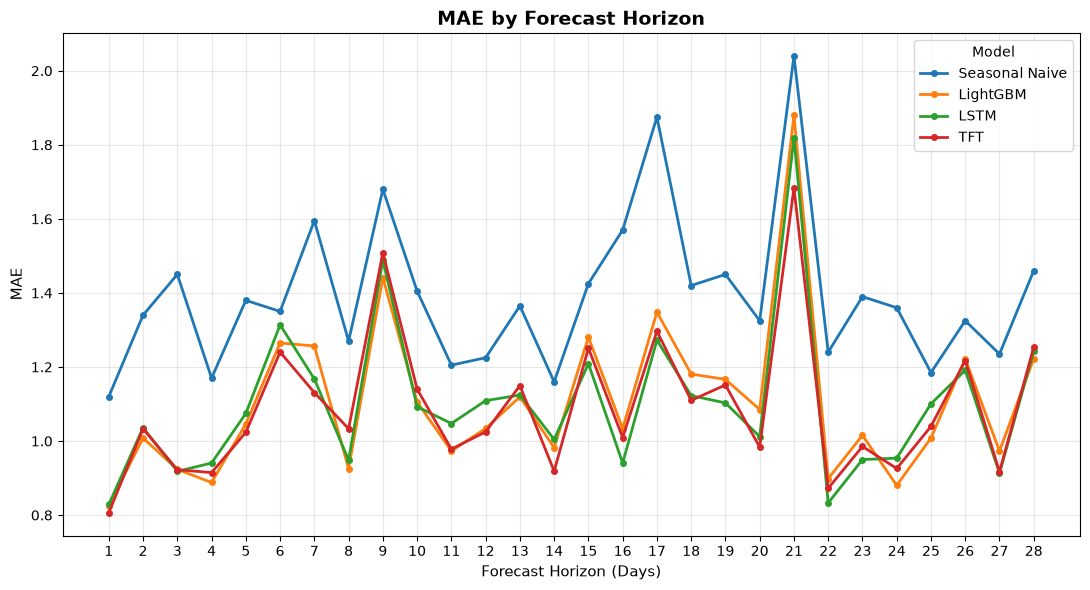

Saved: results\official_evaluation\graphs\official_mae_by_horizon.png


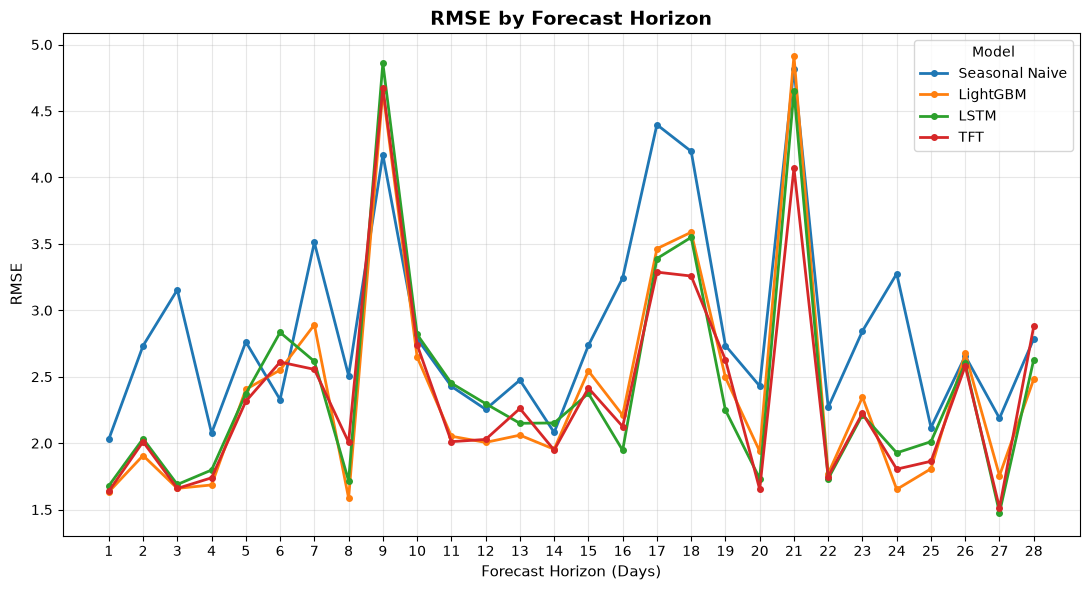

Saved: results\official_evaluation\graphs\official_rmse_by_horizon.png


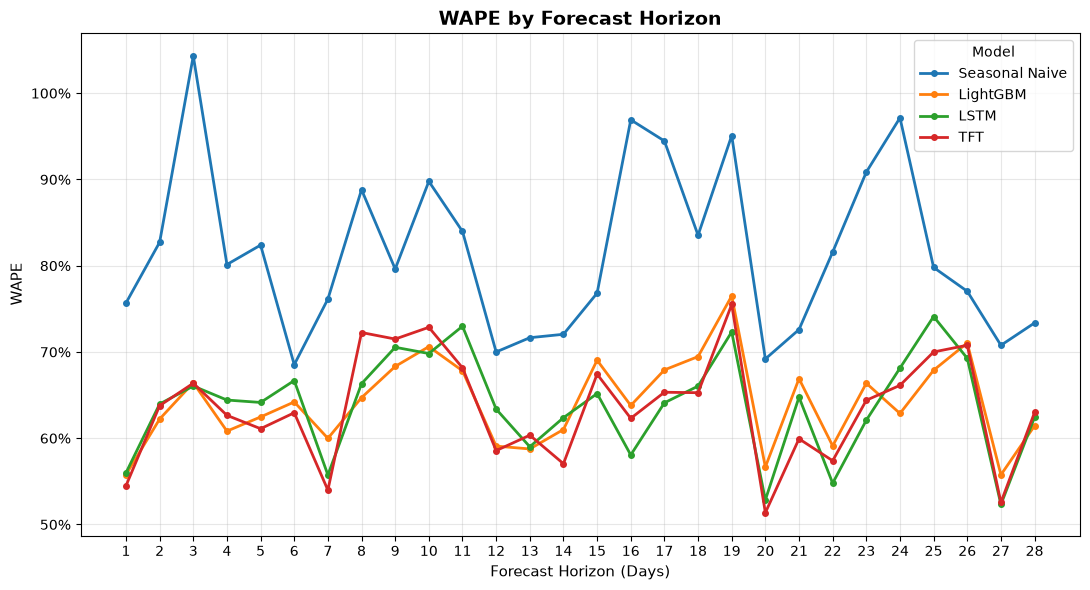

Saved: results\official_evaluation\graphs\official_wape_by_horizon.png

All forecast horizon graphs generated.


In [81]:
import matplotlib.pyplot as plt
from pathlib import Path

METRICS = ["MAE", "RMSE", "WAPE"]

MODEL_ORDER = [
    "Seasonal Naive",
    "LightGBM",
    "LSTM",
    "TFT"
]

# Ensure output directory exists.
GRAPH_DIR = RESULTS_DIR / "graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

# Plot each metric separately.
for metric in METRICS:

    fig, ax = plt.subplots(figsize=(11, 6))

    for model_name in MODEL_ORDER:

        model_data = (
            horizon_metrics[
                horizon_metrics["model"] == model_name
            ]
            .sort_values("horizon")
        )

        ax.plot(
            model_data["horizon"],
            model_data[metric],
            marker="o",
            markersize=4,
            linewidth=2,
            label=model_name
        )

    ax.set_title(
        f"{metric} by Forecast Horizon",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Forecast Horizon (Days)", fontsize=11)
    ax.set_ylabel(metric, fontsize=11)

    ax.set_xticks(range(1, 29))
    ax.grid(True, alpha=0.3)
    ax.legend(title="Model")

    if metric == "WAPE":
        ax.yaxis.set_major_formatter(
            plt.FuncFormatter(lambda x, _: f"{x:.0%}")
        )

    plt.tight_layout()

    # Save graph.
    graph_path = GRAPH_DIR / f"official_{metric.lower()}_by_horizon.png"

    plt.savefig(
        graph_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {graph_path}")

print("\nAll forecast horizon graphs generated.")

In [82]:
import itertools

N_BOOTSTRAP = 2000
BOOTSTRAP_SEED = 42
CONFIDENCE_LEVEL = 0.95

rng = np.random.default_rng(BOOTSTRAP_SEED)

# Use the same observations and actual values for all models.
model_predictions = {}

for model_name, df in official_predictions.items():

    ordered = (
        df.sort_values(KEY_COLUMNS)
        .reset_index(drop=True)
    )

    if model_name == "Seasonal Naive":
        prediction_col = (
            "prediction_p50"
            if "prediction_p50" in ordered.columns
            else "forecast"
        )
    else:
        prediction_col = "prediction_p50"

    model_predictions[model_name] = ordered[
        ["id", "actual_sales", prediction_col]
    ].rename(columns={
        prediction_col: "prediction"
    })

# Construct a common evaluation matrix.
comparison = reference[["id", "actual_sales"]].copy()

for model_name in MODEL_NAMES:

    comparison[f"{model_name}_prediction"] = (
        model_predictions[model_name]["prediction"].to_numpy()
    )

series_ids = comparison["id"].unique()
n_series = len(series_ids)

series_row_indices = {
    series_id: np.flatnonzero(
        comparison["id"].to_numpy() == series_id
    )
    for series_id in series_ids
}

def calculate_metrics(actual, prediction):

    errors = actual - prediction

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    denominator = np.sum(np.abs(actual))

    wape = (
        np.sum(np.abs(errors)) / denominator
        if denominator > 0
        else np.nan
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    }

bootstrap_results = []

model_pairs = list(itertools.combinations(MODEL_NAMES, 2))

for model_a, model_b in model_pairs:

    prediction_a = comparison[
        f"{model_a}_prediction"
    ].to_numpy()

    prediction_b = comparison[
        f"{model_b}_prediction"
    ].to_numpy()

    actual = comparison["actual_sales"].to_numpy()

    observed_a = calculate_metrics(actual, prediction_a)
    observed_b = calculate_metrics(actual, prediction_b)

    bootstrap_differences = {
        "MAE": [],
        "RMSE": [],
        "WAPE": []
    }

    for _ in range(N_BOOTSTRAP):

        sampled_series = rng.choice(
            series_ids,
            size=n_series,
            replace=True
        )

        sampled_indices = np.concatenate([
            series_row_indices[series_id]
            for series_id in sampled_series
        ])

        sampled_actual = actual[sampled_indices]
        sampled_a = prediction_a[sampled_indices]
        sampled_b = prediction_b[sampled_indices]

        metrics_a = calculate_metrics(
            sampled_actual, sampled_a
        )

        metrics_b = calculate_metrics(
            sampled_actual, sampled_b
        )

        for metric in bootstrap_differences:

            bootstrap_differences[metric].append(
                metrics_a[metric] - metrics_b[metric]
            )

    alpha = 1 - CONFIDENCE_LEVEL

    for metric, differences in bootstrap_differences.items():

        lower, upper = np.quantile(
            differences,
            [alpha / 2, 1 - alpha / 2]
        )

        bootstrap_results.append({
            "model_a": model_a,
            "model_b": model_b,
            "metric": metric,
            "observed_difference_a_minus_b": (
                observed_a[metric] - observed_b[metric]
            ),
            "confidence_level": CONFIDENCE_LEVEL,
            "CI_lower": lower,
            "CI_upper": upper,
            "bootstrap_iterations": N_BOOTSTRAP
        })

bootstrap_comparison = pd.DataFrame(bootstrap_results)

display(bootstrap_comparison.round(5))

bootstrap_comparison.to_csv(
    RESULTS_DIR / "official_paired_cluster_bootstrap.csv",
    index=False
)

print("Saved paired cluster bootstrap results.")

,model_a,model_b,metric,observed_difference_a_minus_b,confidence_level,CI_lower,CI_upper,bootstrap_iterations
0,Seasonal Naive,LightGBM,MAE,0.28665,0.95,0.22248,0.35874,2000
1,Seasonal Naive,LightGBM,RMSE,0.40496,0.95,0.24551,0.62324,2000
2,Seasonal Naive,LightGBM,WAPE,0.16619,0.95,0.12342,0.21677,2000
3,Seasonal Naive,LSTM,MAE,0.29493,0.95,0.22264,0.37145,2000
4,Seasonal Naive,LSTM,RMSE,0.39170,0.95,0.23389,0.61438,2000
5,Seasonal Naive,LSTM,WAPE,0.17099,0.95,0.12657,0.22586,2000
6,Seasonal Naive,TFT,MAE,0.30334,0.95,0.23706,0.37563,2000
7,Seasonal Naive,TFT,RMSE,0.47455,0.95,0.30412,0.67481,2000
8,Seasonal Naive,TFT,WAPE,0.17587,0.95,0.13548,0.22837,2000
9,LightGBM,LSTM,MAE,0.00827,0.95,-0.02147,0.03377,2000


Saved paired cluster bootstrap results.


## Final Conclusion
The evaluation demonstrates that all three machine learning models (LightGBM, LSTM and TFT) outperform the Seasonal Naive baseline across overall forecasting metrics. TFT achieves the best overall point-forecasting performance, recording the lowest MAE (1.0901), RMSE (2.4758) and WAPE (63.20%).

Performance differences between the three machine learning models are relatively small. Paired cluster-bootstrap confidence intervals indicate that all three outperform Seasonal Naive, but do not establish a statistically significant overall advantage for TFT over LightGBM. TFT shows a lower RMSE than LSTM, although this finding is based on an unadjusted comparison.

Across demand categories, TFT performs particularly well for lumpy and smooth demand, while LSTM achieves the lowest MAE for intermittent and erratic demand. However, the erratic category contains only three series, limiting the reliability of that comparison.

Probabilistic forecasting results show differences in interval coverage and quantile crossing. These results suggest that forecasting accuracy alone is insufficient to determine operational suitability; uncertainty estimates should also be considered.
Recommended Model: Temporal Fusion Transformer (TFT)
Selected model
TFT is the recommended model for the final platform because:
- It achieves the best overall MAE, RMSE and WAPE.
- It performs particularly well on lumpy and smooth demand.
- It has the lowest quantile crossing rate (0.25%), indicating better ordering consistency between predicted quantiles.
- Its attention-based architecture provides mechanisms for interpreting temporal relationships and feature importance.
Final decision: Use TFT as the primary forecasting model for the retail demand intelligence platform. Retain LightGBM as a benchmark or alternative due to its competitive accuracy and simpler deployment characteristics.

The selection is based on the current 200-series, 28-day official evaluation. TFT should not be described as statistically superior to every competing model. Further operational validation and calibration assessment would be appropriate before production deployment.